# Lab3: Bayes' and kNN classifier

### 1. Bayes’ classifier

#### Gathering images

Three images were downloaded: two reference images representing urban and forest areas, and one test image covering both types of terrain. All images contain RGB channels.

forest=(44, 47, 3), city=(44, 53, 3), test=(219, 352, 3), common scale=1.0, max raw=0.528
band order: raster bands 1,2,3 -> R,G,B; test CRS=EPSG:32634


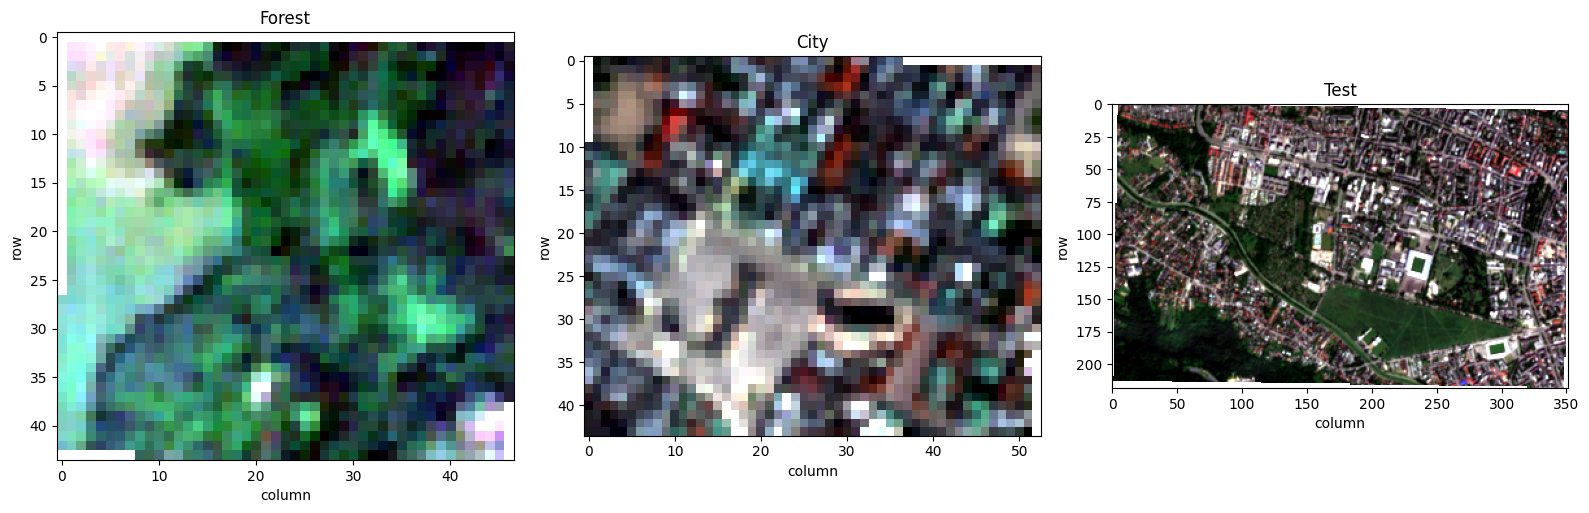

In [2]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import rasterio

LAB3=Path.cwd()
if not (LAB3/'S2_RGB.tif').exists(): LAB3=Path(r'C:/Users/HP/Desktop/stuff/ML_for_space/ML4Space/Lab3')

def read_rgb(path):
    with rasterio.open(path) as src:
        return np.moveaxis(src.read(),0,-1).astype(np.float32),src.profile.copy()

forest_raw,forest_profile=read_rgb(LAB3/'S2_forest.tif')
city_raw,city_profile=read_rgb(LAB3/'S2_city.tif')
test_raw,test_profile=read_rgb(LAB3/'S2_RGB.tif')
all_max=max(float(np.nanmax(x)) for x in (forest_raw,city_raw,test_raw))
SCALE=10000.0 if all_max>255 else (255.0 if all_max>1.5 else 1.0)
forest=np.clip(forest_raw/SCALE,0,1); city=np.clip(city_raw/SCALE,0,1); test=np.clip(test_raw/SCALE,0,1)
print(f'forest={forest.shape}, city={city.shape}, test={test.shape}, common scale={SCALE}, max raw={all_max:.3f}')
print(f'band order: raster bands 1,2,3 -> R,G,B; test CRS={test_profile.get("crs")}')

def display_rgb(img):
    lo=np.nanpercentile(img,2,axis=(0,1)); hi=np.nanpercentile(img,98,axis=(0,1)); return np.clip((img-lo)/(hi-lo+1e-12),0,1)
fig,ax=plt.subplots(1,3,figsize=(16,5))
for a,img,title in zip(ax,[forest,city,test],['Forest','City','Test']):
    a.imshow(display_rgb(img)); a.set_title(title); a.set_xlabel('column'); a.set_ylabel('row')
plt.tight_layout(); plt.show()

#### Histograms for reference images

Forest: n=1981, mu=[0.02629321 0.05332835 0.02802167], sigma=[0.00615722 0.01016482 0.00399434], prior=0.5
City: n=2296, mu=[0.11836438 0.11470759 0.10215154], sigma=[0.04192565 0.03972331 0.03723938], prior=0.5


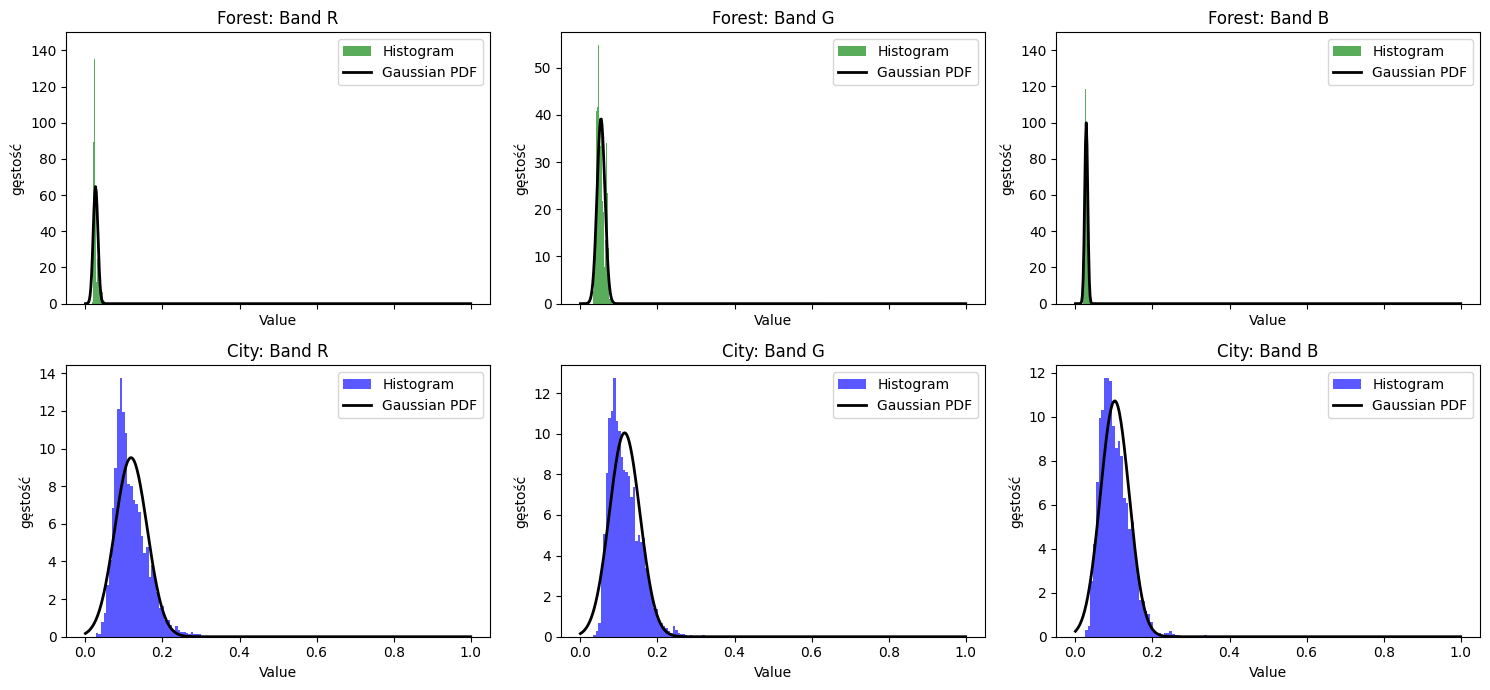

In [4]:
def pixels(img):
    x=img.reshape(-1,3); return x[np.isfinite(x).all(axis=1)]
X_forest=pixels(forest); X_city=pixels(city)
X_train=np.vstack([X_forest,X_city]); y_train=np.r_[np.zeros(len(X_forest),int),np.ones(len(X_city),int)]
class_names=['Forest','City']; means=np.vstack([X_forest.mean(0),X_city.mean(0)]); stds=np.maximum(np.vstack([X_forest.std(0),X_city.std(0)]),1e-8); priors=np.array([.5,.5])
for c,n in enumerate(class_names): print(f'{n}: n={sum(y_train==c)}, mu={means[c]}, sigma={stds[c]}, prior={priors[c]}')
grid=np.linspace(0,1,500); fig,ax=plt.subplots(2,3,figsize=(15,7),sharex=True)
for c,n in enumerate(class_names):
    for j,b in enumerate('RGB'):
        v=X_train[y_train==c,j]; ax[c,j].hist(v,bins=45,density=True,alpha=.65,color=['green','blue'][c],label='Histogram')
        pdf=np.exp(-.5*((grid-means[c,j])/stds[c,j])**2)/(np.sqrt(2*np.pi)*stds[c,j]); ax[c,j].plot(grid,pdf,'k',lw=2,label='Gaussian PDF')
        ax[c,j].set_title(f'{n}: Band {b}'); ax[c,j].set_xlabel('Value'); ax[c,j].set_ylabel('gęstość'); ax[c,j].legend()
plt.tight_layout(); plt.show()

#### Bayes test for new Image

The Bayesian classifier determines whether each pixel belongs to a forest or urban area based on its RGB values. It calculates the probability of the pixel belonging to each class using the previously estimated Gaussian distributions. The pixel is then assigned to the class with the highest probability: forest (red) or urban (blue).

Bayes hold-out accuracy=0.9907
S2_RGB: forest=25250, city=51838


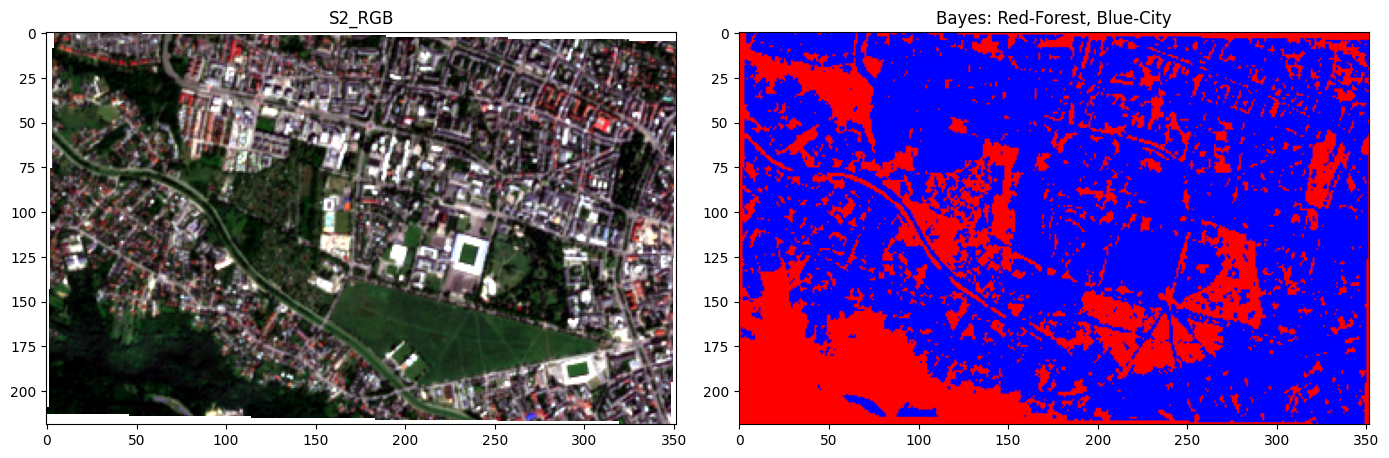

In [5]:
def gaussian_logpdf(X,mu,sigma): return (-.5*(((X-mu)/sigma)**2+np.log(2*np.pi*sigma**2))).sum(1)
def bayes_predict(X):
    scores=np.column_stack([gaussian_logpdf(X,means[c],stds[c])+np.log(priors[c]) for c in range(2)]); return scores.argmax(1),scores
def class_rgb(mask):
    out=np.zeros((*mask.shape,3)); out[mask==0]=[1,0,0]; out[mask==1]=[0,0,1]; return out
perm=np.random.default_rng(2026).permutation(len(X_train)); hold_idx=perm[int(.8*len(perm)):]
p,_=bayes_predict(X_train[hold_idx]); print(f'Bayes hold-out accuracy={(p==y_train[hold_idx]).mean():.4f}')
bayes_mask=bayes_predict(test.reshape(-1,3))[0].reshape(test.shape[:2]); print(f'S2_RGB: forest={(bayes_mask==0).sum()}, city={(bayes_mask==1).sum()}')
fig,ax=plt.subplots(1,2,figsize=(14,5)); ax[0].imshow(display_rgb(test)); ax[0].set_title('S2_RGB'); ax[1].imshow(class_rgb(bayes_mask)); ax[1].set_title('Bayes: Red-Forest, Blue-City')

plt.tight_layout(); plt.show()

### 2. kNN classifier

The kNN classifier selects reference pixels from both forest and urban classes, ensuring an equal number of samples for each class. It calculates the Euclidean distance between each test pixel and all reference pixels based on their RGB values, then identifies the k nearest neighbours. Each test pixel is assigned to the class (forest or urban) that occurs most frequently among its nearest neighbours.

k=1: hold-out accuracy=0.9988
k=3: hold-out accuracy=0.9965
k=5: hold-out accuracy=0.9965
k-NN stride=1, queries=77088


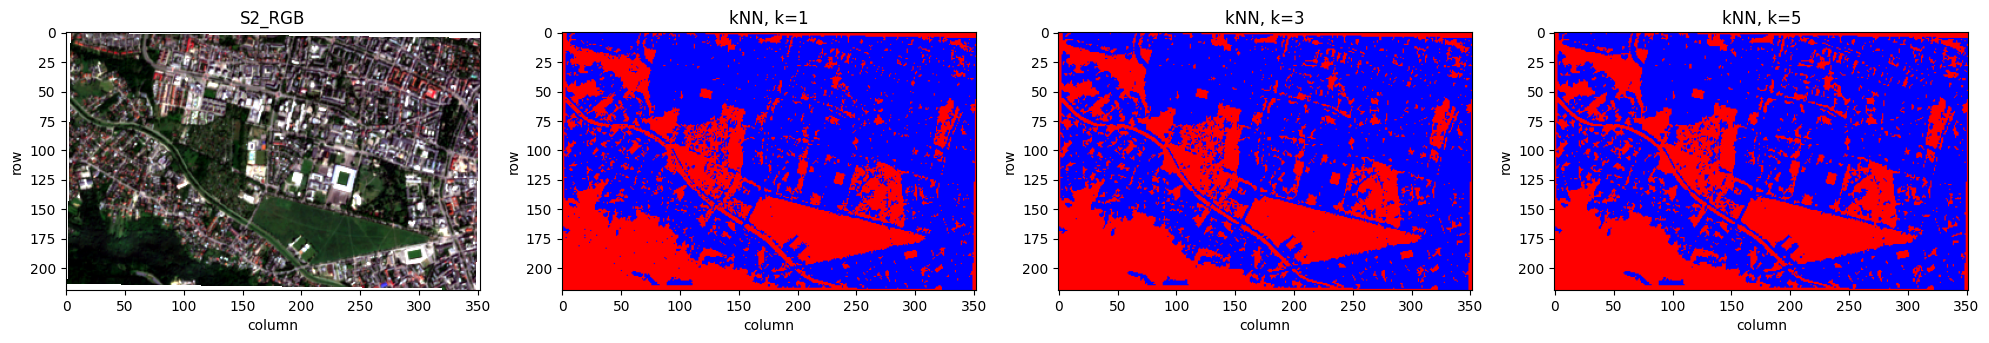

In [14]:
rng=np.random.default_rng(42); nref=min(1200,len(X_forest),len(X_city)); refidx=np.concatenate([rng.choice(np.flatnonzero(y_train==c),nref,False) for c in range(2)]); Xref,yref=X_train[refidx],y_train[refidx]
def knn_predict(Q,R,y,k,batch_size=512):
    out=np.empty(len(Q),int)
    for start in range(0,len(Q),batch_size):
        q=Q[start:start+batch_size]; dist2=((q[:,None,:]-R[None,:,:])**2).sum(2); ids=np.argpartition(dist2,k-1,axis=1)[:,:k]
        for i,ii in enumerate(ids): out[start+i]=np.bincount(y[ii],minlength=2).argmax()
    return out
for k in (1,3,5):
    p=knn_predict(X_train[hold_idx],Xref,yref,k); print(f'k={k}: hold-out accuracy={(p==y_train[hold_idx]).mean():.4f}')

max_queries=180000; stride=max(1,int(np.ceil(np.sqrt(test.shape[0]*test.shape[1]/max_queries)))); test_knn=test[::stride,::stride]; print(f'k-NN stride={stride}, queries={test_knn.shape[0]*test_knn.shape[1]}')
fig,ax=plt.subplots(1,4,figsize=(20,5)); ax[0].imshow(display_rgb(test)); ax[0].set_title('S2_RGB')
for a,k in zip(ax[1:],(1,3,5)):
    m=knn_predict(test_knn.reshape(-1,3),Xref,yref,k).reshape(test_knn.shape[:2]); a.imshow(class_rgb(m)); a.set_title(f'kNN, k={k}')
for a in ax: a.set_xlabel('column'); a.set_ylabel('row')
plt.tight_layout(); plt.show()

No noticeable visual differences can be observed between the classification results for k = 1, 3, and 5. Although the value of k changes the number of neighbours considered during classification, the overall results remain very similar.

The lack of noticeable differences between k = 1, 3, and 5 may indicate that forest and urban pixels are relatively well separated in the RGB feature space. As a result, increasing the number of neighbours does not significantly change outcome.